In [1]:
import numpy as np
import pandas
import matplotlib.pyplot as plt
import cv2

In [2]:
def convert_color(image):
    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

In [3]:
capture = cv2.VideoCapture(r"D:\Deployemnt\vtest.avi")

In [6]:
capture.get(cv2.CAP_PROP_FRAME_COUNT)

795.0

In [7]:
import numpy as np

In [9]:
random_frames = capture.get(cv2.CAP_PROP_FRAME_COUNT) * np.random.uniform(size=30)

In [10]:
random_frames

array([353.26201847, 664.66660585,  53.75247086, 242.29010058,
       143.28774223, 587.94515622, 140.07401246, 412.91701013,
       145.6548246 , 458.06544286, 645.40634216, 779.57770772,
       677.88168805, 569.98195987, 712.80950202, 322.09858708,
       662.027936  , 294.27690477, 544.99058029, 346.52986184,
        25.75251836, 135.8534419 , 789.17369558, 729.27107341,
       314.93864583, 283.19498841, 293.25203905, 390.45998977,
       425.88312026, 483.68780711])

In [11]:
frames = []
for frame_id in random_frames:
    capture.set(cv2.CAP_PROP_POS_FRAMES, frame_id)
    ret, frame = capture.read()
    frames.append(frame)
capture.release()

In [12]:
frames

[array([[[102, 139, 172],
         [103, 140, 173],
         [104, 141, 174],
         ...,
         [ 56,  79, 105],
         [ 70,  80, 106],
         [ 45,  55,  81]],
 
        [[101, 138, 171],
         [102, 139, 172],
         [104, 141, 174],
         ...,
         [ 56,  79, 105],
         [ 72,  82, 108],
         [ 48,  58,  84]],
 
        [[102, 139, 172],
         [103, 140, 173],
         [104, 141, 174],
         ...,
         [ 58,  81, 107],
         [ 62,  72,  98],
         [ 42,  52,  78]],
 
        ...,
 
        [[  0,  28,  13],
         [  0,  32,  17],
         [  0,  36,  21],
         ...,
         [ 10,  71,  57],
         [ 13,  74,  60],
         [ 13,  74,  60]],
 
        [[  0,  29,  14],
         [  0,  33,  18],
         [  0,  37,  22],
         ...,
         [  7,  67,  56],
         [  8,  71,  59],
         [ 11,  74,  62]],
 
        [[  0,  30,  15],
         [  0,  34,  19],
         [  0,  39,  24],
         ...,
         [ 13,  73,  62],
  

In [13]:
len(frames)

30

In [14]:
frames[0]

array([[[102, 139, 172],
        [103, 140, 173],
        [104, 141, 174],
        ...,
        [ 56,  79, 105],
        [ 70,  80, 106],
        [ 45,  55,  81]],

       [[101, 138, 171],
        [102, 139, 172],
        [104, 141, 174],
        ...,
        [ 56,  79, 105],
        [ 72,  82, 108],
        [ 48,  58,  84]],

       [[102, 139, 172],
        [103, 140, 173],
        [104, 141, 174],
        ...,
        [ 58,  81, 107],
        [ 62,  72,  98],
        [ 42,  52,  78]],

       ...,

       [[  0,  28,  13],
        [  0,  32,  17],
        [  0,  36,  21],
        ...,
        [ 10,  71,  57],
        [ 13,  74,  60],
        [ 13,  74,  60]],

       [[  0,  29,  14],
        [  0,  33,  18],
        [  0,  37,  22],
        ...,
        [  7,  67,  56],
        [  8,  71,  59],
        [ 11,  74,  62]],

       [[  0,  30,  15],
        [  0,  34,  19],
        [  0,  39,  24],
        ...,
        [ 13,  73,  62],
        [ 13,  76,  64],
        [ 14,  77,  65]]

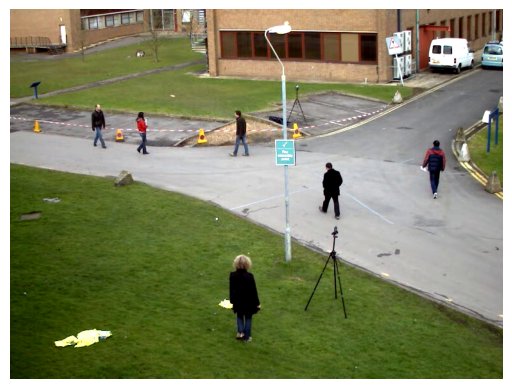

In [16]:
plt.imshow(convert_color(frames[10]))
plt.axis('off')
plt.show()

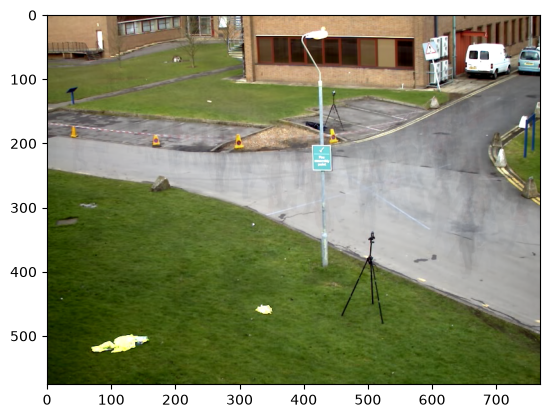

In [21]:
avg_frame = np.average(frames, axis=0).astype(np.uint8)
plt.imshow(convert_color(avg_frame))

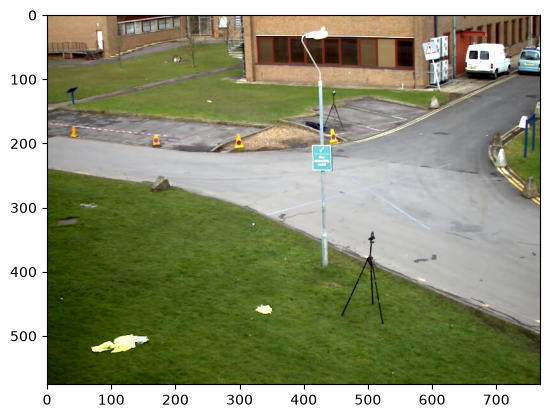

In [19]:
avg_frame = np.median(frames, axis=0).astype(np.uint8)
plt.imshow(convert_color(avg_frame))

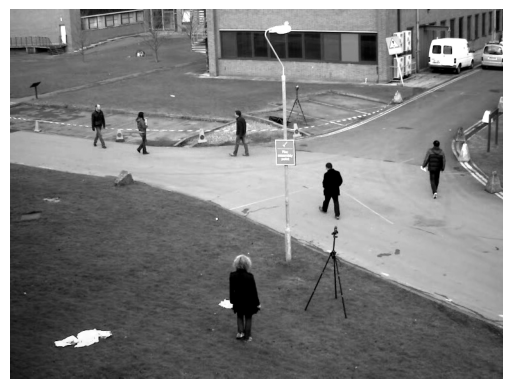

In [22]:
framex = frames[10]
gray_frame = cv2.cvtColor(framex, cv2.COLOR_BGR2GRAY)
plt.imshow(gray_frame, cmap='gray')
plt.axis('off')
plt.show()

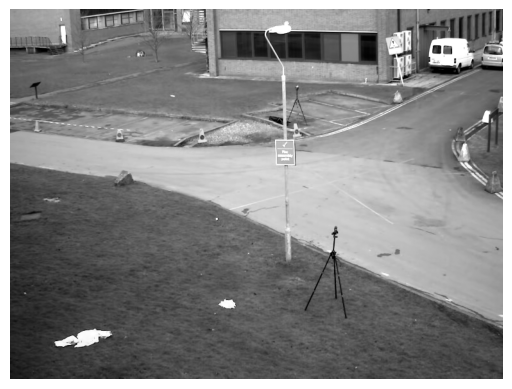

In [24]:
# extract background from grayscale frames
background = np.median(frames, axis=0).astype(np.uint8)
gray_background = cv2.cvtColor(background, cv2.COLOR_BGR2GRAY)
plt.imshow(gray_background, cmap='gray')
plt.axis('off')
plt.show()

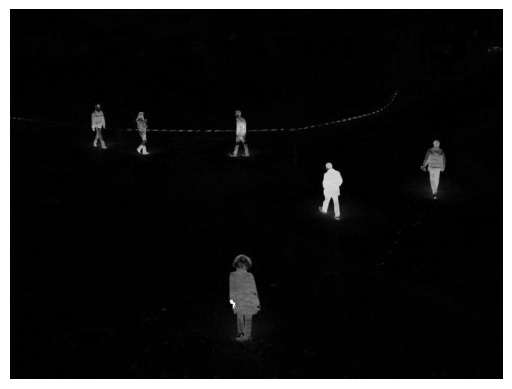

In [25]:
background_removed = cv2.absdiff(gray_frame, gray_background)
plt.imshow(background_removed, cmap='gray')
plt.axis('off')
plt.show()

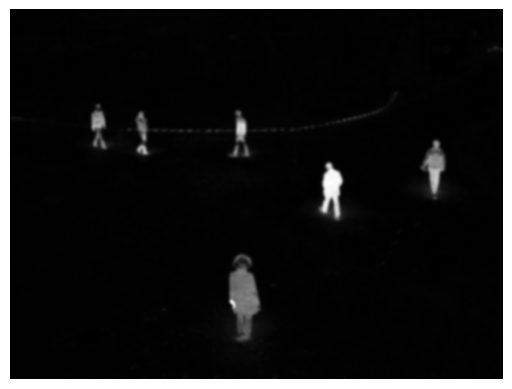

In [26]:
background_removed_blured = cv2.GaussianBlur(background_removed, (11, 11), 0)
plt.imshow(background_removed_blured, cmap='gray')
plt.axis('off')
plt.show()

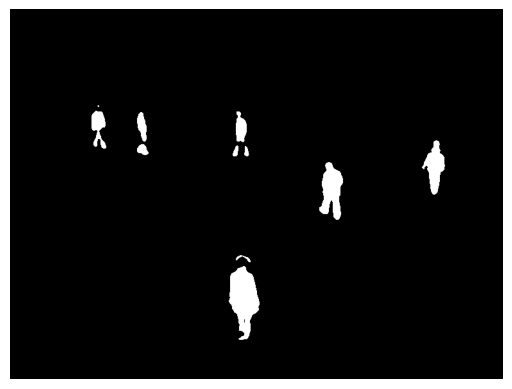

In [27]:
_, frame_tr = cv2.threshold(background_removed_blured, 0, 255, cv2.THRESH_BINARY+cv2.THRESH_OTSU)
plt.imshow(frame_tr, cmap='gray')
plt.axis('off')
plt.show()

In [28]:
(controus, _) = cv2.findContours(frame_tr, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

In [29]:
len(controus)

11

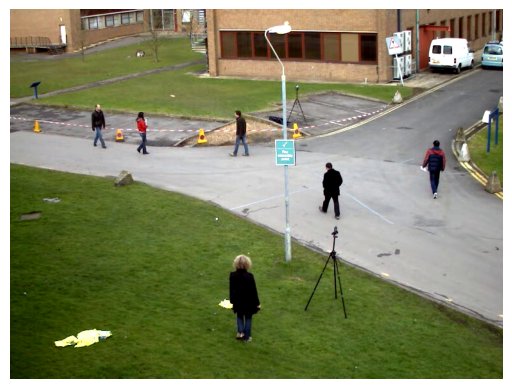

In [31]:
plt.imshow(convert_color(framex))
plt.axis('off')
plt.show()

In [32]:
for contour in controus:
    x, y, w, h = cv2.boundingRect(contour)
    cv2.rectangle(framex, (x, y), (x+w, y+h), (0, 255, 0), 2)

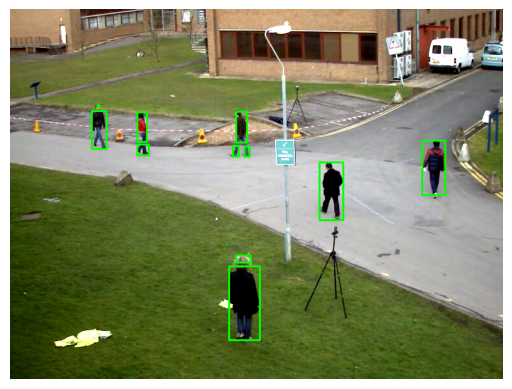

In [33]:
plt.imshow(convert_color(framex))
plt.axis('off')
plt.show()

Apply `createBackgroundSubtractor` on the whole video

In [4]:
background_subtractor = cv2.createBackgroundSubtractorMOG2()
capture = cv2.VideoCapture(r"D:\Deployemnt\vtest.avi")
while capture.isOpened():
    ret, frame = capture.read()

    if not ret:
        break

    fg_mask = background_subtractor.apply(frame)
    (controus, _) = cv2.findContours(fg_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    for contour in controus:
        if cv2.contourArea(contour) > 500:
            x, y, w, h = cv2.boundingRect(contour)
            cv2.rectangle(frame, (x, y), (x+w, y+h), (0, 255, 0), 2)

    cv2.imshow('Frame', frame)
    cv2.imshow('FGMask', fg_mask)

    if cv2.waitKey(30) & 0xFF == ord('q'):
        break

capture.release()
cv2.destroyAllWindows()